In [15]:
import sys, importlib
from pathlib import Path
import pandas as pd

sys.path.insert(0, str(Path("..").resolve()))

CACHE = Path("../data/interim/sheets_raw")
key = "ID_UC_G0"
SKIP = ("Description", "Index")
sheets = {p.stem: pd.read_parquet(p) for p in CACHE.glob("*.parquet")}
print(len(sheets), "листов загружено")

txt = (Path("..") / "src" / "cleaning.py").read_text(encoding="utf-8")
print("cleaning.py:", len(txt.splitlines()), "строк | build_clean есть:", "def build_clean" in txt)

17 листов загружено
cleaning.py: 313 строк | build_clean есть: True


In [16]:
import src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import clean_sheet, build_clean

final, stats = {}, []
for n, d in sheets.items():
    if n in SKIP:
        continue
    final[n], st = clean_sheet(d, key)
    stats.append({"лист": n, **st})
print(len(final), "листов очищено")

15 листов очищено


In [5]:
import sys
from pathlib import Path
import pandas as pd

# чтобы работал import src.*
sys.path.insert(0, str(Path("..").resolve()))

# автоподхват правок в src/*.py без перезапуска ядра
%load_ext autoreload
%autoreload 2

RAW = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
CACHE = Path("../data/interim/sheets_raw")
key = "ID_UC_G0"

if CACHE.exists() and any(CACHE.glob("*.parquet")):
    sheets = {p.stem: pd.read_parquet(p) for p in CACHE.glob("*.parquet")}
else:
    sheets = pd.read_excel(RAW, sheet_name=None)
    CACHE.mkdir(parents=True, exist_ok=True)
    for name, d in sheets.items():
        if name in ("Index", "Description"):
            d = d.astype("string")
        d.to_parquet(CACHE / f"{name}.parquet")

print(len(sheets), "листов загружено")

17 листов загружено


In [17]:
clean_final, rep = build_clean(final, key, sheets["Index"])
print(clean_final.shape, "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"],
      "| выбросы:", rep["выбросы_log_iqr"])

(1089, 2619) | строк с долей вне 0-100: 48 | выбросы: {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


In [6]:
import pandas as pd
xlsx = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
print(pd.ExcelFile(xlsx).sheet_names)

['Description', 'Index', 'GENERAL_CHARACTERISTICS', 'GHSL', 'CLIMATE', 'EMISSIONS', 'EXPOSURE', 'GEOGRAPHY', 'GREENNESS', 'HAZARD_RISK', 'HEALTH', 'INFRASTRUCTURES', 'LULC', 'NATURAL_SYSTEMS', 'SDG', 'SOCIOECONOMIC', 'WATER']


In [7]:
%%time
sheets = pd.read_excel(xlsx, sheet_name=None)  
for name, d in sheets.items():
    print(f"{name:28s} {d.shape}")

Description                  (31, 3)
Index                        (506, 29)
GENERAL_CHARACTERISTICS      (1089, 13)
GHSL                         (1089, 551)
CLIMATE                      (1089, 109)
EMISSIONS                    (1089, 590)
EXPOSURE                     (1089, 1066)
GEOGRAPHY                    (1089, 37)
GREENNESS                    (1089, 63)
HAZARD_RISK                  (1089, 118)
HEALTH                       (1089, 17)
INFRASTRUCTURES              (1089, 17)
LULC                         (1089, 49)
NATURAL_SYSTEMS              (1091, 23)
SDG                          (1089, 43)
SOCIOECONOMIC                (1089, 183)
WATER                        (1089, 28)
CPU times: total: 15.2 s
Wall time: 15.3 s


In [8]:
display(sheets["Description"].head(30))
display(sheets["GENERAL_CHARACTERISTICS"].iloc[:3, :12])
common = set.intersection(*(set(d.columns) for n, d in sheets.items() if n not in ("Description", "Index")))
print(common)


,Name,GHS-UCDB R2024A - GHS Urban Centre Database 2025,Unnamed: 2
0,Dataset ID,GHS-UCDB R2024A,NaN
1,Version,V1.2,NaN
2,Data Last Update,15/05/2026,NaN
3,Alternative name (with version),GHS Urban Centre Database 2024 - GHS Urban Cen...,NaN
4,Accronym,GHS-UCDB 2025 R2024A V1.2,NaN
5,Authors,"Mari Rivero, Ines; Melchiorri, Michele; Florio...",NaN
6,Document Version,V1.1,NaN
7,Document Last Update,30/07/2025,NaN
8,NaN,NaN,NaN
9,Contact point,JRC-GHSL<at>EC.EUROPA.EU,GHSL project related questions


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025,GC_CNT_GAD_2025,GC_CNT_UNN_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025,GC_DEV_USR_2025,GC_PLS_SCR_2025,GC_UCB_YOB_2025,GC_UCB_YOD_2025
0,5,Rosarito,Rosarito,MÃ©xico,Mexico,29,76707.05999,Upper Middle,Latin America and the Caribbean,High,2015,2030
1,7,Malacatán,MalacatÃ¡n,Guatemala,Guatemala,9,62529.14530,Upper Middle,Latin America and the Caribbean,High,2015,2030
2,8,Ahuachapan,Ahuachapan,El Salvador,El Salvador,19,83851.12663,Upper Middle,Latin America and the Caribbean,High,1980,2030


{'GC_POP_TOT_2025', 'GC_CNT_GAD_2025', 'GC_UCA_KM2_2025', 'GC_UCN_MAI_2025', 'ID_UC_G0', 'GC_DEV_WIG_2025', 'GC_DEV_USR_2025'}


In [9]:
key = "ID_UC_G0"
for name, d in sheets.items():
    if name in ("Description", "Index"):
        continue
    has = key in d.columns
    print(f"{name:24s} ключ_есть={has}  строк={len(d)}  "
          f"уникальных={d[key].nunique() if has else '-'}  "
          f"пропусков={d[key].isna().sum() if has else '-'}")

GENERAL_CHARACTERISTICS  ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GHSL                     ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
CLIMATE                  ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
EMISSIONS                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
EXPOSURE                 ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GEOGRAPHY                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
GREENNESS                ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
HAZARD_RISK              ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
HEALTH                   ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
INFRASTRUCTURES          ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
LULC                     ключ_есть=True  строк=1089  уникальных=1089  пропусков=0
NATURAL_SYSTEMS          ключ_есть=True  строк=1091  уникальных=1089  пропусков=0
SDG             

In [10]:
ns = sheets["NATURAL_SYSTEMS"]
base = set(sheets["GENERAL_CHARACTERISTICS"][key])
display(ns[~ns[key].isin(base)].iloc[:, :6])        # строки, которых нет в основном листе
display(ns[ns[key].duplicated(keep=False)].iloc[:, :6])   # дубликаты по ключу


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_UCA_KM2_2025,GC_POP_TOT_2025,GC_DEV_WIG_2025
686,4943,Cúcuta,Colombia,114,817158.1235,Upper Middle
687,4943,Cúcuta,Colombia,114,817158.1235,Upper Middle
858,6621,Reynosa,MÃ©xico,155,616127.2669,Upper Middle
859,6621,Reynosa,MÃ©xico,155,616127.2669,Upper Middle


In [11]:
g = sheets["GENERAL_CHARACTERISTICS"]
txt = g.select_dtypes("object")
bad = {c: txt[c].astype(str).str.contains("Ã|Â", regex=True).sum() for c in txt}
print({c: n for c, n in bad.items() if n})

{'GC_UCN_MAI_2025': np.int64(1), 'GC_UCN_LIS_2025': np.int64(345), 'GC_CNT_GAD_2025': np.int64(183), 'GC_CNT_UNN_2025': np.int64(1)}


C:\Users\Артём\AppData\Local\Temp\ipykernel_15352\63697357.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  txt = g.select_dtypes("object")


In [12]:
ns = sheets["NATURAL_SYSTEMS"]
print("полных дубликатов строк:", ns.duplicated().sum())


полных дубликатов строк: 0


In [13]:
import src, importlib
print(src.__path__)
print(sorted(p.name for p in Path(src.__path__[0]).iterdir()))
importlib.invalidate_caches()
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))

['C:\\Users\\Артём\\Desktop\\аналитиии\\src']
['__init__.py', '__pycache__', 'cleaning.py', 'inspect_raw.py', 'src']
313 строк записано


ImportError: cannot import name 'fix_mojibake' from 'src.cleaning' (C:\Users\Артём\Desktop\аналитиии\src\cleaning.py)

In [ ]:
import sys
sys.path.insert(0, str(Path("..").resolve()))   # блокнот лежит в notebooks/, src/ на уровень выше

%load_ext autoreload
%autoreload 2
from src.cleaning import fix_mojibake

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
def fix_mojibake(s):
    """Чинит только строки с признаками двойного кодирования UTF-8."""
    if not isinstance(s, str) or not any(m in s for m in ("Ã", "Â")):
        return s
    for enc in ("cp1252", "latin-1"):
        try:
            return s.encode(enc).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            continue
    return s  # не удалось, оставляем как есть

g = sheets["GENERAL_CHARACTERISTICS"]
cols = ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025", "GC_CNT_GAD_2025", "GC_CNT_UNN_2025"]
fixed = g[cols].map(fix_mojibake)

for c in cols:
    m = fixed[c].fillna("") != g[c].fillna("")
    print(c, "исправлено:", m.sum())
    display(pd.DataFrame({"было": g.loc[m, c], "стало": fixed.loc[m, c]}).drop_duplicates().head(8))

print(fixed.apply(lambda s: s.astype(str).str.contains("Ã|Â")).sum())  # что осталось битым

GC_UCN_MAI_2025 исправлено: 0


,было,стало


GC_UCN_LIS_2025 исправлено: 345


,было,стало
1,MalacatÃ¡n,Malacatán
10,San AndrÃ©s,San Andrés
15,UreÃ±a,Ureña
16,JÃ©rÃ©mie,Jérémie
29,ConcepciÃ³n,Concepción
35,CofradÃ­a,Cofradía
36,LeÃ³n,León
40,ColÃ³n,Colón


GC_CNT_GAD_2025 исправлено: 183


,было,стало
0,MÃ©xico,México
20,CuraÃ§ao,Curaçao


GC_CNT_UNN_2025 исправлено: 1


,было,стало
20,CuraÃ§ao,Curaçao


GC_UCN_MAI_2025    1
GC_UCN_LIS_2025    1
GC_CNT_GAD_2025    0
GC_CNT_UNN_2025    0
dtype: int64


In [ ]:
for name, d in sheets.items():
    if name in ("Description", "Index"):
        continue
    t = d.select_dtypes(include=["object", "string"])
    bad = {c: int(t[c].astype(str).str.contains("Ã|Â").sum()) for c in t.columns}
    bad = {c: n for c, n in bad.items() if n}
    if bad:
        print(name, bad)

GENERAL_CHARACTERISTICS {'GC_UCN_MAI_2025': 1, 'GC_UCN_LIS_2025': 345, 'GC_CNT_GAD_2025': 183, 'GC_CNT_UNN_2025': 1}
GHSL {'GC_UCN_MAI_2025': 1}
CLIMATE {'GC_UCN_MAI_2025': 1}
EMISSIONS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
EXPOSURE {'GC_UCN_MAI_2025': 1}
GEOGRAPHY {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183, 'GE_ECO_CLA_2025': 164}
GREENNESS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
HAZARD_RISK {'GC_UCN_MAI_2025': 1}
HEALTH {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
INFRASTRUCTURES {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
LULC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
NATURAL_SYSTEMS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 184, 'NS_MPA_NAM_2025': 31, 'NS_TPA_NAM_2025': 192, 'NS_TPA_DES_202': 1}
SDG {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
SOCIOECONOMIC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
WATER {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}


GENERAL_CHARACTERISTICS {'GC_UCN_MAI_2025': 1, 'GC_UCN_LIS_2025': 345, 'GC_CNT_GAD_2025': 183, 'GC_CNT_UNN_2025': 1}
GHSL {'GC_UCN_MAI_2025': 1}
CLIMATE {'GC_UCN_MAI_2025': 1}
EMISSIONS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
EXPOSURE {'GC_UCN_MAI_2025': 1}
GEOGRAPHY {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183, 'GE_ECO_CLA_2025': 164}
GREENNESS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
HAZARD_RISK {'GC_UCN_MAI_2025': 1}
HEALTH {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
INFRASTRUCTURES {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
LULC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
NATURAL_SYSTEMS {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 184, 'NS_MPA_NAM_2025': 31, 'NS_TPA_NAM_2025': 192, 'NS_TPA_DES_202': 1}
SDG {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
SOCIOECONOMIC {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}
WATER {'GC_UCN_MAI_2025': 1, 'GC_CNT_GAD_2025': 183}


In [ ]:
sheets["Index"].astype("string").to_parquet(CACHE / "Index.parquet")
print(len(list(CACHE.glob("*.parquet"))), "файлов в кэше")   # ожидаем 16


17 файлов в кэше


In [ ]:
for name, d in sheets.items():
    d.astype("string").to_parquet(CACHE / f"{name}.parquet") if name in ("Index", "Description") \
        else d.to_parquet(CACHE / f"{name}.parquet")
    

In [ ]:
ns = sheets["NATURAL_SYSTEMS"]
dup = ns[ns[key].duplicated(keep=False)].sort_values(key)
diff_cols = [c for c in dup.columns if dup.groupby(key)[c].nunique(dropna=False).gt(1).any()]
print(len(diff_cols), diff_cols)
display(dup[[key] + diff_cols].T)

1 ['NS_TPA_PER_2025']


,686,687,858,859
ID_UC_G0,4943.000000,4943.000000,6621.000000,6621.000000
NS_TPA_PER_2025,0.041406,0.002576,1.428053,0.104751


In [ ]:
for name, d in sheets.items():
    d.astype("string").to_parquet(CACHE / f"{name}.parquet") if name in ("Index", "Description") \
        else d.to_parquet(CACHE / f"{name}.parquet")
    

In [ ]:
g = sheets["GENERAL_CHARACTERISTICS"]
cols = ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025", "GC_CNT_GAD_2025", "GC_CNT_UNN_2025"]
fixed = g[cols].map(fix_mojibake)

for c in ["GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]:
    m = fixed[c].astype(str).str.contains("Ã|Â")
    display(g.loc[m, [key, c]].assign(после=fixed.loc[m, c]))

,ID_UC_G0,GC_UCN_MAI_2025,после
510,3496,Santo Ângelo,Santo Ângelo


,ID_UC_G0,GC_UCN_LIS_2025,после
510,3496,Santo Ãngelo,Santo Ângelo


In [ ]:
p = Path(src.__path__[0])
print(sorted(x.name for x in (p / "src").iterdir()))

[]


In [ ]:
import shutil
shutil.move(str(p / "src" / "cleaning.py"), str(p / "cleaning.py"))
print(sorted(x.name for x in p.iterdir()))

FileNotFoundError: [WinError 2] Не удается найти указанный файл

In [ ]:
importlib.invalidate_caches()
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))   # México

México


In [ ]:
print(repr((Path("..") / "src" / "cleaning.py").read_text(encoding="utf-8")[:300]))

'"""Функции очистки данных GHS-UCDB."""\nimport re\nimport numpy as np\nimport pandas as pd\nimport logging\n\nlogger = logging.getLogger(__name__)\n_BAD = re.compile(r"Ã[\\u0080-\\u00BF]|[\\u0080-\\u009F]")\n_THOUSANDS = re.compile(r"^\\d{1,3}(,\\d{3})+(\\.\\d+)?$")\n\nPLACEHOLDERS = {"", "-", "--", "n/a", "na", "nan'


In [ ]:
code = '''"""Функции очистки данных GHS-UCDB."""


def fix_mojibake(s):
    """Чинит только строки с признаками двойного кодирования UTF-8."""
    if not isinstance(s, str) or not any(m in s for m in ("Ã", "Â")):
        return s
    for enc in ("cp1252", "latin-1"):
        try:
            return s.encode(enc).decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            continue
    return s
'''
(Path("..") / "src" / "cleaning.py").write_text(code, encoding="utf-8")

import importlib, sys
importlib.invalidate_caches()
import src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import fix_mojibake
print(fix_mojibake("MÃ©xico"))   # México

México


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import fix_text_columns, count_mojibake

ImportError: cannot import name 'fix_text_columns' from 'src.cleaning' (C:\Users\Артём\Desktop\аналитиии\src\cleaning.py)

In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import fix_text_columns, count_mojibake

SKIP = ("Description", "Index")
before = {n: count_mojibake(d) for n, d in sheets.items() if n not in SKIP}
clean_sheets = {n: (d if n in SKIP else fix_text_columns(d)) for n, d in sheets.items()}
after = {n: count_mojibake(d) for n, d in clean_sheets.items() if n not in SKIP}

print("было значений с порчей:", sum(sum(v.values()) for v in before.values()))
print("осталось:", sum(sum(v.values()) for v in after.values()))
print({n: v for n, v in after.items() if v})

again = {n: count_mojibake(fix_text_columns(d)) for n, d in clean_sheets.items() if n not in SKIP}
print("повторное применение ничего не меняет:", again == after)

ImportError: cannot import name 'fix_text_columns' from 'src.cleaning' (C:\Users\Артём\Desktop\аналитиии\src\cleaning.py)

In [ ]:
from src.cleaning import _BAD

g2 = clean_sheets["GENERAL_CHARACTERISTICS"]
m = g2["GC_UCN_LIS_2025"].map(lambda s: isinstance(s, str) and _BAD.search(s) is not None)

display(g2.loc[m, [key, "GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]])
display(sheets["GENERAL_CHARACTERISTICS"].loc[m, [key, "GC_UCN_MAI_2025", "GC_UCN_LIS_2025"]])  # до очистки

for s in g2.loc[m, "GC_UCN_LIS_2025"]:
    print([(ch, hex(ord(ch))) for ch in s if ord(ch) > 127])

,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025


,ID_UC_G0,GC_UCN_MAI_2025,GC_UCN_LIS_2025


In [ ]:
ns = sheets["NATURAL_SYSTEMS"]
dup = ns[ns[key].duplicated(keep=False)].sort_values(key)

idx = sheets["Index"]
mask = idx.astype(str).apply(lambda col: col.str.contains("NS_TPA_PER", na=False)).any(axis=1)
display(idx[mask].dropna(axis=1, how="all").T)

cols = [c for c in ns.columns if c.startswith("NS_TPA")]
display(dup[[key] + cols].T)

,450
Indicator Name,Share of Terrestrial Protected Areas in the ur...
Attribute ID,NS_TPA_PER_XXXX
Unit,%
Methodology,Spatial Join


,686,687,858,859
ID_UC_G0,4943,4943,6621,6621
NS_TPA_NAM_2025,Bosque Seco Tropical Pozo Azul ; Aguas Calientes,Bosque Seco Tropical Pozo Azul ; Aguas Calientes,Laguna La Escondida ; Lower Rio Grande Valley ...,Laguna La Escondida ; Lower Rio Grande Valley ...
NS_TPA_DES_202,Integrated Management Regional Districts ; Nat...,Integrated Management Regional Districts ; Nat...,State Park ; Marine Protected Area ; National ...,State Park ; Marine Protected Area ; National ...
NS_TPA_PER_2025,0.041406,0.002576,1.428053,0.104751


In [ ]:
import sqlite3
gpkg = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.gpkg")
con = sqlite3.connect(gpkg.resolve().as_uri() + "?mode=ro", uri=True)

tables = pd.read_sql("SELECT table_name, data_type FROM gpkg_contents", con)
print(tables)
layer = tables.loc[tables.data_type == "features", "table_name"].iloc[0]
cols = pd.read_sql(f'PRAGMA table_info("{layer}")', con)["name"].tolist()
print(len(cols), [c for c in cols if "TPA" in c])

if "NS_TPA_PER_2025" in cols:
    display(pd.read_sql(
        f'SELECT {key}, NS_TPA_PER_2025 FROM "{layer}" WHERE {key} IN (4943, 6621)', con))
con.close()

                                           table_name data_type
0   GHSL_UCDB_THEME_GENERAL_CHARACTERISTICS_GLOBE_...  features
1                   GHSL_UCDB_THEME_GHSL_GLOBE_R2024A  features
2                GHSL_UCDB_THEME_CLIMATE_GLOBE_R2024A  features
3              GHSL_UCDB_THEME_EMISSIONS_GLOBE_R2024A  features
4               GHSL_UCDB_THEME_EXPOSURE_GLOBE_R2024A  features
5              GHSL_UCDB_THEME_GEOGRAPHY_GLOBE_R2024A  features
6              GHSL_UCDB_THEME_GREENNESS_GLOBE_R2024A  features
7            GHSL_UCDB_THEME_HAZARD_RISK_GLOBE_R2024A  features
8                 GHSL_UCDB_THEME_HEALTH_GLOBE_R2024A  features
9        GHSL_UCDB_THEME_INFRASTRUCTURES_GLOBE_R2024A  features
10                  GHSL_UCDB_THEME_LULC_GLOBE_R2024A  features
11       GHSL_UCDB_THEME_NATURAL_SYSTEMS_GLOBE_R2024A  features
12                   GHSL_UCDB_THEME_SDG_GLOBE_R2024A  features
13         GHSL_UCDB_THEME_SOCIOECONOMIC_GLOBE_R2024A  features
14                 GHSL_UCDB_THEME_WATER

In [ ]:
for n, d in sheets.items():
    if n in ("Description", "Index"):
        continue
    odd = [c for c in d.columns if not c.endswith("_2025") and c != key]
    if odd:
        print(n, odd)

GENERAL_CHARACTERISTICS ['GC_UCM_CAP']
GHSL ['GH_BUS_TOT_1975', 'GH_BUS_TOT_1980', 'GH_BUS_TOT_1985', 'GH_BUS_TOT_1990', 'GH_BUS_TOT_1995', 'GH_BUS_TOT_2000', 'GH_BUS_TOT_2005', 'GH_BUS_TOT_2010', 'GH_BUS_TOT_2015', 'GH_BUS_TOT_2020', 'GH_BUS_TOT_2030', 'GH_BUS_NRE_1975', 'GH_BUS_NRE_1980', 'GH_BUS_NRE_1985', 'GH_BUS_NRE_1990', 'GH_BUS_NRE_1995', 'GH_BUS_NRE_2000', 'GH_BUS_NRE_2005', 'GH_BUS_NRE_2010', 'GH_BUS_NRE_2015', 'GH_BUS_NRE_2020', 'GH_BUS_NRE_2030', 'GH_BUS_RES_1975', 'GH_BUS_RES_1980', 'GH_BUS_RES_1985', 'GH_BUS_RES_1990', 'GH_BUS_RES_1995', 'GH_BUS_RES_2000', 'GH_BUS_RES_2005', 'GH_BUS_RES_2010', 'GH_BUS_RES_2015', 'GH_BUS_RES_2020', 'GH_BUS_RES_2030', 'GH_BPC_TOT_1975', 'GH_BPC_TOT_1980', 'GH_BPC_TOT_1985', 'GH_BPC_TOT_1990', 'GH_BPC_TOT_1995', 'GH_BPC_TOT_2000', 'GH_BPC_TOT_2005', 'GH_BPC_TOT_2010', 'GH_BPC_TOT_2015', 'GH_BPC_TOT_2020', 'GH_BPC_TOT_2030', 'GH_BPC_NRE_1975', 'GH_BPC_NRE_1980', 'GH_BPC_NRE_1985', 'GH_BPC_NRE_1990', 'GH_BPC_NRE_1995', 'GH_BPC_NRE_2000', 'GH_B

In [ ]:
con = sqlite3.connect(gpkg.resolve().as_uri() + "?mode=ro", uri=True)
layer = next(t for t in tables.table_name if "NATURAL_SYSTEMS" in t)

print(layer)
print(pd.read_sql(f'SELECT COUNT(*) AS строк, COUNT(DISTINCT {key}) AS уникальных FROM "{layer}"', con))
display(pd.read_sql(
    f'SELECT {key}, NS_TPA_PER_2025 FROM "{layer}" WHERE {key} IN (4943, 6621)', con))
con.close()

GHSL_UCDB_THEME_NATURAL_SYSTEMS_GLOBE_R2024A
   строк  уникальных
0   1091        1089


,ID_UC_G0,NS_TPA_PER_2025
0,4943,0.041406
1,4943,0.002576
2,6621,1.428053
3,6621,0.104751


In [ ]:
import re
for n, d in sheets.items():
    if n in ("Description", "Index"):
        continue
    odd = [c for c in d.columns if c != key and not re.search(r"_(19|20)\d{2}$", c)]
    if odd:
        print(n, odd)

GENERAL_CHARACTERISTICS ['GC_UCM_CAP']
EXPOSURE ['Unnamed: 0_x', 'Unnamed: 0_y', 'Unnamed: 0']
NATURAL_SYSTEMS ['NS_TPA_DES_202']


In [ ]:
ex = sheets["EXPOSURE"]
junk = ["Unnamed: 0_x", "Unnamed: 0_y", "Unnamed: 0"]
display(ex[junk].head())
display(ex[junk].describe().T)

,Unnamed: 0_x,Unnamed: 0_y,Unnamed: 0
0,4.0,4.0,4.0
1,6.0,6.0,6.0
2,7.0,7.0,7.0
3,8.0,8.0,8.0
4,9.0,9.0,9.0


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0_x,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0
Unnamed: 0_y,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0
Unnamed: 0,675.0,2564.731852,2018.370694,4.0,1043.5,2247.0,3489.5,8407.0


In [ ]:
m = idx.astype(str).apply(lambda col: col.str.contains("UCM_CAP", na=False)).any(axis=1)
display(idx[m].dropna(axis=1, how="all").T)

,15
Group,Urban Centre Municipality
Indicator Name,Country Capital
Attribute ID,GC_UCM_CAP_XXXX
Source,"Wikipedia, GoogleMaps"
Methodology,Geoencoding
Note,boolean


In [ ]:
from src.cleaning import rename_truncated_columns, drop_service_columns, drop_key_duplicates

ns_c = clean_sheets["NATURAL_SYSTEMS"]
ns2 = drop_key_duplicates(rename_truncated_columns(ns_c), key)
print(len(ns_c), "->", len(ns2))
display(ns2.loc[ns2["dup_key_flag"], [key, "NS_TPA_PER_2025", "dup_key_flag"]])

ex2 = drop_service_columns(clean_sheets["EXPOSURE"])
print(clean_sheets["EXPOSURE"].shape, "->", ex2.shape)

1091 -> 1089


,ID_UC_G0,NS_TPA_PER_2025,dup_key_flag
686,4943,0.041406,True
857,6621,1.428053,True


(1089, 1066) -> (1089, 1063)


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
print([f for f in dir(src.cleaning) if not f.startswith("__")])

['CENSORED', 'COLUMN_RENAMES', 'MAX_MISSING_SHARE', 'OUTLIER_COLUMNS', 'PLACEHOLDERS', '_BAD', '_THOUSANDS', '_YEAR', '_is_text', '_looks_broken', '_to_number', 'add_outlier_flags', 'attr_id', 'build_clean', 'clean_sheet', 'column_units', 'count_mojibake', 'drop_constant_columns', 'drop_key_duplicates', 'drop_service_columns', 'find_censored_columns', 'find_constant_columns', 'find_numeric_text_columns', 'find_sparse_columns', 'fix_censored_numeric', 'fix_mojibake', 'fix_numeric_text', 'fix_text_columns', 'flag_out_of_range', 'logger', 'logging', 'merge_sheets', 'normalize_column_names', 'np', 'outlier_masks', 'pd', 're', 'rename_truncated_columns']


In [ ]:
ex = sheets["EXPOSURE"]
u = ex["Unnamed: 0"]
print("три столбца совпадают:", ex["Unnamed: 0_x"].equals(u) and ex["Unnamed: 0_y"].equals(u))
print("столбец с ключом:", (ex[key] - u).dropna().value_counts().head(5).to_dict())
print("пропусков:", u.isna().sum(), "из", len(u))

три столбца совпадают: True
столбец с ключом: {1.0: 675}
пропусков: 414 из 1089


In [ ]:
SENT = [-9999, -999, -99, -1, 9999]
PLACEHOLDERS = {"", "-", "--", "n/a", "na", "nan", "none", "null", "unknown", "no data"}

na_rows, sent_rows, txt_rows = [], [], []
for n, d in clean_sheets.items():
    if n in SKIP:
        continue
    for c in d.columns:
        if c == key:
            continue
        s = d[c]
        na_rows.append((n, c, s.isna().mean()))
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_numeric_dtype(s):
            for v in SENT:
                k = int((s == v).sum())
                if k:
                    sent_rows.append((n, c, v, k))
        elif pd.api.types.is_string_dtype(s):
            k = int(s.astype("string").str.strip().str.lower().isin(PLACEHOLDERS).sum())
            if k:
                txt_rows.append((n, c, k))

na_df = pd.DataFrame(na_rows, columns=["лист", "столбец", "доля_NaN"])
print("столбцов проверено:", len(na_df), "| с пропусками:", int((na_df["доля_NaN"] > 0).sum()))
display(na_df.groupby("лист")["доля_NaN"].agg(["mean", "max"]).round(3))
display(na_df.sort_values("доля_NaN", ascending=False).head(10))

sent_df = pd.DataFrame(sent_rows, columns=["лист", "столбец", "значение", "штук"])
display(sent_df.groupby("значение")["штук"].agg(["count", "sum"]))
display(sent_df.sort_values("штук", ascending=False).head(10))

display(pd.DataFrame(txt_rows, columns=["лист", "столбец", "штук"]).sort_values("штук", ascending=False).head(10))

столбцов проверено: 2892 | с пропусками: 540


,mean,max
лист,,
CLIMATE,0.065,0.973
EMISSIONS,0.000,0.002
EXPOSURE,0.095,0.380
GENERAL_CHARACTERISTICS,0.000,0.002
GEOGRAPHY,0.028,0.493
GHSL,0.000,0.005
GREENNESS,0.001,0.028
HAZARD_RISK,0.208,0.999
HEALTH,0.196,0.479


,лист,столбец,доля_NaN
2710,SOCIOECONOMIC,SC_SEC_GDI_1990,1.0
2801,SOCIOECONOMIC,SC_SEC_GIM_1990,1.0
2802,SOCIOECONOMIC,SC_SEC_GIM_1995,1.0
2794,SOCIOECONOMIC,SC_SEC_GIF_1990,1.0
2788,SOCIOECONOMIC,SC_SEC_SYM_1995,1.0
2746,SOCIOECONOMIC,SC_SEC_LEM_1995,1.0
2745,SOCIOECONOMIC,SC_SEC_LEM_1990,1.0
2739,SOCIOECONOMIC,SC_SEC_LEF_1995,1.0
2738,SOCIOECONOMIC,SC_SEC_LEF_1990,1.0
2725,SOCIOECONOMIC,SC_SEC_GDM_1995,1.0


,count,sum
значение,,
9999,4,4


,лист,столбец,значение,штук
0,GHSL,GH_XST_S11_1975,9999,1
1,EXPOSURE,EX_010_NRE_2030,9999,1
2,EXPOSURE,EX_100_NRE_2030,9999,1
3,EXPOSURE,EX_CF2_BUS_2015,9999,1


,лист,столбец,штук
0,EMISSIONS,EM_PM2_MOR_2000,9
2,EMISSIONS,EM_PM2_MOR_2010,4
3,EMISSIONS,EM_PM2_MOR_2015,4
4,EMISSIONS,EM_PM2_MOR_2020,2
1,EMISSIONS,EM_PM2_MOR_2005,1


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import (fix_text_columns, count_mojibake, rename_truncated_columns,
                          drop_service_columns, drop_key_duplicates)

# кодировка: было / осталось / идемпотентность
before = {n: count_mojibake(d) for n, d in sheets.items() if n not in SKIP}
clean_sheets = {n: (d if n in SKIP else fix_text_columns(d)) for n, d in sheets.items()}
after = {n: count_mojibake(d) for n, d in clean_sheets.items() if n not in SKIP}
print("было:", sum(sum(v.values()) for v in before.values()),
      "| осталось:", sum(sum(v.values()) for v in after.values()))

# дубликаты и служебные столбцы
ns_c = clean_sheets["NATURAL_SYSTEMS"]
ns2 = drop_key_duplicates(rename_truncated_columns(ns_c), key)
print(len(ns_c), "->", len(ns2))
display(ns2.loc[ns2["dup_key_flag"], [key, "NS_TPA_PER_2025", "dup_key_flag"]])

ex2 = drop_service_columns(clean_sheets["EXPOSURE"])
print(clean_sheets["EXPOSURE"].shape, "->", ex2.shape)

было: 2749 | осталось: 0
1091 -> 1089


,ID_UC_G0,NS_TPA_PER_2025,dup_key_flag
686,4943,0.041406,True
857,6621,1.428053,True


(1089, 1066) -> (1089, 1063)


In [ ]:
idx = sheets["Index"]
def describe_attr(prefix):
    m = idx.astype(str).apply(lambda col: col.str.contains(prefix, na=False)).any(axis=1)
    return idx[m].dropna(axis=1, how="all")

for n, c in [("GHSL", "GH_XST_S11_1975"), ("EXPOSURE", "EX_010_NRE_2030"),
             ("EXPOSURE", "EX_100_NRE_2030"), ("EXPOSURE", "EX_CF2_BUS_2015")]:
    s = clean_sheets[n][c]
    print(n, c, "| топ-5:", s.nlargest(5).tolist(), "| медиана:", round(float(s.median()), 2))

display(pd.concat([describe_attr(p) for p in ("GH_XST_S11", "EX_010_NRE", "EX_CF2_BUS")]))

e = clean_sheets["EMISSIONS"]["EM_PM2_MOR_2000"].astype("string")
bad = e[pd.to_numeric(e, errors="coerce").isna() & e.notna()]
print(bad.map(repr).value_counts())

GHSL GH_XST_S11_1975 | топ-5: [2823670, 1257858, 987476, 961255, 817454] | медиана: 0.0
EXPOSURE EX_010_NRE_2030 | топ-5: [13963325, 5122122, 3020221, 2893494, 2689908] | медиана: 0.0
EXPOSURE EX_100_NRE_2030 | топ-5: [13963325, 5122122, 3020221, 2893494, 2689908] | медиана: 0.0
EXPOSURE EX_CF2_BUS_2015 | топ-5: [3491098, 1378888, 1144025, 1024328, 1017025] | медиана: 0.0


,Group,Indicator Name,Unnamed: 3,Attribute ID,Unit,Source,Methodology
55,DOU Cross statistics,BU surface,BU surface in SMOD 11,GH_XST_S11_XXXX,m2,"GHS-BUILT-S R2023A, GHS-SMOD R2023A",Zonal statistics (sum)
219,NaN,NaN,Non-residential built-up exposed to 10 years ...,EX_010_NRE_XXXX,m2,NaN,Zonal statistics (sum)
270,NaN,Built-up exposed,Built-up exposed to coastal floods with a ret...,EX_CF2_BUS_XXXX,m2,"Vousdoukas, M.I, et al (2018), Dottori, F. et ...",Zonal statistics (sum)


EM_PM2_MOR_2000
' -   '    9
'1,275'    1
'1,504'    1
'1,334'    1
'3,454'    1
'4,375'    1
'2,172'    1
Name: count, dtype: int64


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
print([f for f in dir(src.cleaning) if not f.startswith("_") and f.islower()])

['add_outlier_flags', 'attr_id', 'build_clean', 'clean_sheet', 'column_units', 'count_mojibake', 'drop_constant_columns', 'drop_key_duplicates', 'drop_service_columns', 'find_censored_columns', 'find_constant_columns', 'find_numeric_text_columns', 'find_sparse_columns', 'fix_censored_numeric', 'fix_mojibake', 'fix_numeric_text', 'fix_text_columns', 'flag_out_of_range', 'logger', 'logging', 'merge_sheets', 'normalize_column_names', 'np', 'outlier_masks', 'pd', 're', 'rename_truncated_columns']


In [ ]:
display(describe_attr("EM_PM2_MOR"))
for y in (2000, 2005, 2010, 2015, 2020):
    s = clean_sheets["EMISSIONS"][f"EM_PM2_MOR_{y}"]
    nums = pd.to_numeric(s, errors="coerce")
    print(y, "| чисел:", int(nums.notna().sum()), "| макс:", nums.max(),
          "| есть дробные:", bool((nums.dropna() % 1 != 0).any()),
          "| строк-значений:", int(s.map(lambda v: isinstance(v, str)).sum()))

,Group,Indicator Name,Attribute ID,Unit,Source,Methodology
211,Mortality,Premature deaths due to PM2.5 concentrations,EM_PM2_MOR_XXXX,Number of premature deaths,"Belis et al. (2023), GHS-POP R2023A",Modelled


2000 | чисел: 1074 | макс: 4593.0 | есть дробные: False | строк-значений: 1089
2005 | чисел: 1082 | макс: 5428.0 | есть дробные: False | строк-значений: 1089
2010 | чисел: 1078 | макс: 5427.0 | есть дробные: False | строк-значений: 1089
2015 | чисел: 1077 | макс: 6443.0 | есть дробные: False | строк-значений: 1089
2020 | чисел: 1079 | макс: 5721.0 | есть дробные: False | строк-значений: 1089


In [ ]:
from src.cleaning import find_numeric_text_columns, fix_numeric_text
for n, d in clean_sheets.items():
    if n in SKIP:
        continue
    found = find_numeric_text_columns(d)
    if found:
        print(n, found)

EMISSIONS ['EM_PM2_MOR_2000', 'EM_PM2_MOR_2005', 'EM_PM2_MOR_2010', 'EM_PM2_MOR_2015', 'EM_PM2_MOR_2020']
SDG ['SD_LUE_LPR_1975_1980', 'SD_LUE_LPR_2020_2030']


In [ ]:
ex = clean_sheets["EXPOSURE"]
cols = ["EX_L10_SHP_2030", "EX_L05_RES_1990", "EX_L05_SNR_2015", "EX_L05_B12_2020"]
miss = ex[cols].isna()
print("в 4 столбцах пропущены одни и те же строки:", bool(miss.nunique(axis=1).eq(1).all()))
print("совпадают со служебным столбцом:", bool((miss.iloc[:, 0] == ex["Unnamed: 0"].isna()).all()))

gc = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)
m = pd.Series(miss.iloc[:, 0].values, index=ex[key].values)
print(gc["GC_POP_TOT_2025"].reindex(m.index).groupby(m.values).median())
print(m.groupby(gc["GC_CNT_GAD_2025"].reindex(m.index).values).mean()
        .sort_values(ascending=False).head(6).round(2))

в 4 столбцах пропущены одни и те же строки: True
совпадают со служебным столбцом: True
False    110580.4538
True      95771.0729
Name: GC_POP_TOT_2025, dtype: float64
Brazil       0.70
México       0.62
Colombia     0.28
Venezuela    0.16
Argentina    0.16
Belize       0.00
dtype: float64


In [ ]:
from src.cleaning import fix_numeric_text
em_cols = [f"EM_PM2_MOR_{y}" for y in (2000, 2005, 2010, 2015, 2020)]
em = clean_sheets["EMISSIONS"]
em2 = fix_numeric_text(em, em_cols)
for c in em_cols:
    print(c, em[c].dtype, "->", em2[c].dtype,
          "| NaN было/стало:", int(em[c].isna().sum()), "/", int(em2[c].isna().sum()),
          "| значений с запятой:", int(em[c].astype("string").str.contains(",", na=False).sum()),
          "| макс:", em2[c].max())

EM_PM2_MOR_2000 str -> float64 | NaN было/стало: 0 / 9 | значений с запятой: 6 | макс: 4593.0
EM_PM2_MOR_2005 str -> float64 | NaN было/стало: 0 / 1 | значений с запятой: 6 | макс: 5428.0
EM_PM2_MOR_2010 str -> float64 | NaN было/стало: 0 / 4 | значений с запятой: 7 | макс: 5626.0
EM_PM2_MOR_2015 str -> float64 | NaN было/стало: 0 / 4 | значений с запятой: 8 | макс: 6443.0
EM_PM2_MOR_2020 str -> float64 | NaN было/стало: 0 / 2 | значений с запятой: 8 | макс: 5721.0


In [ ]:
sd = clean_sheets["SDG"]
for c in ["SD_LUE_LPR_1975_1980", "SD_LUE_LPR_2020_2030"]:
    s = sd[c]
    nums = pd.to_numeric(s, errors="coerce")
    odd = s[nums.isna() & s.notna()]
    print(c, "| типы:", s.map(lambda v: type(v).__name__).value_counts().to_dict())
    print("  дробные среди чисел:", bool((nums.dropna() % 1 != 0).any()),
          "| диапазон:", nums.min(), nums.max())
    print("  нечисловые:", odd.map(repr).value_counts().head(8).to_dict())
display(describe_attr("SD_LUE_LPR"))

SD_LUE_LPR_1975_1980 | типы: {'str': 1089}
  дробные среди чисел: True | диапазон: -4.917598683 4.931469481
  нечисловые: {"'>5'": 35, "'<-5'": 8}
SD_LUE_LPR_2020_2030 | типы: {'str': 1089}
  дробные среди чисел: True | диапазон: -4.531866206 4.749360781
  нечисловые: {"'>5'": 18, "'<-5'": 14}


,Thematic Area,Group,Indicator Name,Attribute ID,Unit,Source,Methodology
362,SDG,Land Use Efficiency (11.3.1),Land Use Efficiency,SD_LUE_LPR_XXXX_XXXX,dimensionless,"Melchiorri, M. et al (2019)",Definition


In [ ]:
display(describe_attr("EX_L05_RES"))
display(describe_attr("EX_L10_SHP"))

gcx = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)
dfm = gcx.reindex(m.index)[["GC_UCA_KM2_2025", "GC_DEV_WIG_2025"]].assign(пропуск=m.values)
display(dfm.groupby("пропуск")["GC_UCA_KM2_2025"].describe().round(1))
display(pd.crosstab(dfm["GC_DEV_WIG_2025"], dfm["пропуск"], normalize="index").round(2))

ids = pd.Series(m.index, index=m.index)
print(m.groupby(pd.qcut(ids, 5), observed=True).mean().round(2))

,Unnamed: 3,Attribute ID,Unit,Methodology
289,Built-up RES in LECZ (5m),EX_L05_RES_XXXX,m2,Zonal statistics (sum)


,Unnamed: 3,Attribute ID,Unit,Methodology
283,Share of Population living in LECZ (between 5 ...,EX_L10_SHP_XXXX,%,Ratio


,count,mean,std,min,25%,50%,75%,max
пропуск,,,,,,,,
False,675.0,58.9,131.9,3.0,15.0,25.0,48.0,2186.0
True,414.0,55.1,162.2,6.0,16.0,22.0,42.0,2134.0


пропуск,False,True
GC_DEV_WIG_2025,,
High income,1.00,0.00
Lower Middle,1.00,0.00
Upper Middle,0.57,0.43


(4.999, 1371.6]     0.00
(1371.6, 2928.2]    0.00
(2928.2, 4664.8]    0.24
(4664.8, 6718.2]    0.90
(6718.2, 8408.0]    0.77
dtype: float64


In [ ]:
from src.cleaning import find_sparse_columns
sparse = {n: find_sparse_columns(d, key) for n, d in clean_sheets.items() if n not in SKIP}
print({n: len(v) for n, v in sparse.items() if v}, "всего:", sum(len(v) for v in sparse.values()))

{'HAZARD_RISK': 7, 'SOCIOECONOMIC': 22} всего: 29


In [ ]:
from src.cleaning import fix_censored_numeric
lpr = ["SD_LUE_LPR_1975_1980", "SD_LUE_LPR_2020_2030"]
sd2 = fix_censored_numeric(clean_sheets["SDG"], lpr)
for c in lpr:
    print(c, sd2[c].dtype, "| обрезанных:", int(sd2[c + "_cens"].sum()),
          "| диапазон:", sd2[c].min(), sd2[c].max())

SD_LUE_LPR_1975_1980 float64 | обрезанных: 43 | диапазон: -5.0 5.0
SD_LUE_LPR_2020_2030 float64 | обрезанных: 32 | диапазон: -5.0 5.0


In [ ]:
m_idx = idx.astype(str).apply(
    lambda col: col.str.contains("coast|LECZ|elevation", case=False, na=False)).any(axis=1)
display(idx.loc[m_idx, ["Indicator Name", "Attribute ID", "Unit"]].dropna(how="all").head(25))

vals = ex.loc[~miss.iloc[:, 0], cols]
print("доля нулей среди заполненных строк:\n", (vals == 0).mean().round(2))

,Indicator Name,Attribute ID,Unit
113,Average Elevation,GE_ELV_AVG_XXXX,m
268,Population exposed,EX_CF2_POP_XXXX,num inhabitants
269,NaN,EX_CF1_POP_XXXX,num inhabitants
270,Built-up exposed,EX_CF2_BUS_XXXX,m2
271,NaN,EX_CF1_BUS_XXXX,m2
272,NaN,EX_CF2_NRE_XXXX,m2
273,NaN,EX_CF1_NRE_XXXX,m2
274,Share of population exposed,EX_CF2_SHP_XXXX,%
275,NaN,EX_CF1_SHP_XXXX,%
276,Share of built-up exposed,EX_CF2_SHB_XXXX,%


доля нулей среди заполненных строк:
 EX_L10_SHP_2030    0.65
EX_L05_RES_1990    0.67
EX_L05_SNR_2015    1.00
EX_L05_B12_2020    0.73
dtype: float64


In [ ]:
all_sparse = [(n, c) for n, v in sparse.items() for c in v]
pd.DataFrame(all_sparse, columns=["лист", "столбец"]).to_csv("../logs/dropped_sparse_columns.csv", index=False)
print(len(all_sparse), "столбцов в списке на удаление")

29 столбцов в списке на удаление


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import clean_sheet, merge_sheets, count_mojibake

final, stats = {}, []
for n, d in sheets.items():
    if n in SKIP:
        continue
    final[n], st = clean_sheet(d, key)
    stats.append({"лист": n, **st})

stats_df = pd.DataFrame(stats)
display(stats_df.drop(columns="пустые_столбцы").set_index("лист"))

,строк_было,столбцов_было,служебных_удалено,кодировка_исправлено,обрезанных_пределов,текст_в_число,дублей_удалено,пустых_удалено,строк_стало,столбцов_стало
лист,,,,,,,,,,
GENERAL_CHARACTERISTICS,1089,13,0,530,0,0,0,0,1089,13
GHSL,1089,551,0,0,0,0,0,0,1089,551
CLIMATE,1089,109,0,0,0,0,0,0,1089,109
EMISSIONS,1089,590,0,183,0,5,0,0,1089,590
EXPOSURE,1089,1066,3,0,0,0,0,0,1089,1063
GEOGRAPHY,1089,37,0,347,0,0,0,0,1089,37
GREENNESS,1089,63,0,183,0,0,0,0,1089,63
HAZARD_RISK,1089,118,0,0,0,0,0,7,1089,111
HEALTH,1089,17,0,183,0,0,0,0,1089,17


In [ ]:
clean, join_report = merge_sheets(final, key)
display(join_report)

cols_in = sum(d.shape[1] for n, d in sheets.items() if n not in SKIP)
print("столбцов в листах до очистки (с повторами):", cols_in)
print("итоговая таблица:", clean.shape, "| было строк:", len(sheets["GENERAL_CHARACTERISTICS"]))
print("ключ уникален:", clean[key].is_unique, "| пропусков в ключе:", int(clean[key].isna().sum()))
print("остаточных значений с порчей кодировки:", sum(count_mojibake(clean).values()))

const = [c for c in clean.columns if c != key and clean[c].nunique(dropna=True) <= 1]
print(len(const), "константных столбцов:", const[:15])

,лист,строк_до,строк_после,нет_в_базе,нет_в_листе,повторных_столбцов,расхождений_в_повторах
0,GHSL,1089,1089,0,0,6,0
1,CLIMATE,1089,1089,0,0,6,1079
2,EMISSIONS,1089,1089,0,0,6,0
3,EXPOSURE,1089,1089,0,0,6,1079
4,GEOGRAPHY,1089,1089,0,0,6,0
5,GREENNESS,1089,1089,0,0,6,0
6,HAZARD_RISK,1089,1089,0,0,6,1079
7,HEALTH,1089,1089,0,0,6,0
8,INFRASTRUCTURES,1089,1089,0,0,6,0
9,LULC,1089,1089,0,0,6,0


столбцов в листах до очистки (с повторами): 2907
итоговая таблица: (1089, 2787) | было строк: 1089
ключ уникален: True | пропусков в ключе: 0
остаточных значений с порчей кодировки: 0
171 константных столбцов: ['GC_DEV_USR_2025', 'GH_XST_A13_2015', 'GH_XST_A22_2015', 'GH_XST_A13_2020', 'GH_XST_A22_2020', 'GH_XST_A11_2025', 'GH_XST_A12_2025', 'GH_XST_A13_2025', 'GH_XST_A21_2025', 'GH_XST_A22_2025', 'XST_A23_2025', 'GH_XST_S13_2015', 'GH_XST_S22_2015', 'GH_XST_S13_2020', 'GH_XST_S22_2020']


In [ ]:
Path("../data/processed").mkdir(parents=True, exist_ok=True)
clean.to_parquet("../data/processed/clean.parquet", compression="zstd")
print(round(Path("../data/processed/clean.parquet").stat().st_size / 1024**2, 1), "МБ")

11.4 МБ


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
g_raw = sheets["GENERAL_CHARACTERISTICS"]
uniq = sum(count_mojibake(g_raw).values())
for n, d in sheets.items():
    if n in SKIP or n == "GENERAL_CHARACTERISTICS":
        continue
    own = d.drop(columns=[c for c in d.columns if c in g_raw.columns])
    uniq += sum(count_mojibake(own).values())
print("уникальных ячеек с порчей кодировки:", uniq)

уникальных ячеек с порчей кодировки: 918


In [ ]:
base = final["GENERAL_CHARACTERISTICS"].set_index(key)
for n in ("CLIMATE", "EXPOSURE", "HAZARD_RISK", "WATER"):
    d = final[n].set_index(key).reindex(base.index)
    for c in [c for c in d.columns if c in base.columns]:
        a, b = base[c], d[c]
        same = (a == b) | (a.isna() & b.isna())
        if same.all():
            continue
        print(f"{n} | {c} | типы {a.dtype} / {b.dtype} | расхождений: {int((~same).sum())}")
        display(pd.DataFrame({"база": a[~same], n: b[~same]}).head(3))
        if pd.api.types.is_numeric_dtype(a) and pd.api.types.is_numeric_dtype(b):
            rel = ((a - b).abs() / a.abs().where(a != 0))[~same]
            print("   макс. относительная разница:", rel.max())

CLIMATE | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,CLIMATE
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
EXPOSURE | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,EXPOSURE
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
HAZARD_RISK | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,HAZARD_RISK
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08
WATER | GC_POP_TOT_2025 | типы float64 / float64 | расхождений: 1079


,база,WATER
ID_UC_G0,,
5,76707.05999,76707.06
7,62529.14530,62529.15
8,83851.12663,83851.13


   макс. относительная разница: 9.628461002776953e-08


In [ ]:
const = [c for c in clean.columns if c != key and clean[c].nunique(dropna=True) <= 1]
rows = []
for c in const:
    s = clean[c]
    nn = int(s.notna().sum())
    rows.append((c, nn, s.dropna().iloc[0] if nn else None))
cdf = pd.DataFrame(rows, columns=["столбец", "непустых", "значение"])
print(len(cdf), "константных;", int((cdf["непустых"] == 0).sum()), "полностью пустых")
print(cdf["значение"].astype("string").value_counts(dropna=False).head(8))
display(cdf.sort_values("непустых", ascending=False).head(10))

171 константных; 0 полностью пустых
значение
0                                  134
0.0                                 36
Latin America and the Caribbean      1
Name: count, dtype: int64[pyarrow]


,столбец,непустых,значение
0,GC_DEV_USR_2025,1089,Latin America and the Caribbean
1,GH_XST_A13_2015,1089,0
2,GH_XST_A22_2015,1089,0
3,GH_XST_A13_2020,1089,0
4,GH_XST_A22_2020,1089,0
5,GH_XST_A11_2025,1089,0
6,GH_XST_A12_2025,1089,0
7,GH_XST_A13_2025,1089,0
8,GH_XST_A21_2025,1089,0
9,GH_XST_A22_2025,1089,0


In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import attr_id, column_units, find_constant_columns

const = find_constant_columns(clean, key)
units = column_units(clean.columns, sheets["Index"])
idx2 = sheets["Index"].dropna(subset=["Attribute ID"]).copy()
idx2["Attribute ID"] = idx2["Attribute ID"].astype("string").str.strip()
names = idx2.drop_duplicates("Attribute ID").set_index("Attribute ID")["Indicator Name"]

summ = pd.DataFrame({"атрибут": [attr_id(c) for c in const]}).value_counts().reset_index(name="столбцов")
summ["показатель"] = summ["атрибут"].map(names)
display(summ.head(15))
print("всего константных:", len(const), "| из", clean.shape[1] - 1)

,атрибут,столбцов,показатель
0,EX_E10_POP_XXXX,12,NaN
1,EX_E10_BUS_XXXX,12,NaN
2,EX_E10_NRE_XXXX,12,NaN
3,EX_L05_NRE_XXXX,12,NaN
4,EX_L05_SNR_XXXX,12,NaN
5,EX_LEC_SNR_XXXX,12,NaN
6,HZ_CON_VAC_XXXX,4,Number of events per event type
7,HZ_CON_BAT_XXXX,4,NaN
8,HZ_CON_SDV_XXXX,4,NaN
9,HZ_CON_RIO_XXXX,4,NaN


всего константных: 171 | из 2786


In [ ]:
num = clean.select_dtypes("number").drop(columns=[key], errors="ignore")
print("числовых столбцов:", num.shape[1], "| без описания в Index:",
      sum(units.get(c) is None for c in num.columns))

neg = (num < 0).sum()
neg = neg[neg > 0]
rep = pd.DataFrame({"единица": [units.get(c) for c in neg.index], "отрицательных": neg.values}, index=neg.index)
display(rep.groupby("единица", dropna=False)["отрицательных"].agg(["count", "sum"]))
display(rep.sort_values("отрицательных", ascending=False).head(10))

pct = [c for c in num.columns if units.get(c) == "%"]
over = (num[pct] > 100).sum()
print("столбцов в %:", len(pct), "| со значениями больше 100:", int((over > 0).sum()))
display(over[over > 0].sort_values(ascending=False).head(10))

числовых столбцов: 2758 | без описания в Index: 241


,count,sum
единица,,
dimensionless,18,931
°C/year,1,26
NaN,10,673


,единица,отрицательных
GH_POP_CAG_2020,NaN,214
GH_POP_CAG_2025,NaN,147
SD_LUE_PGR_2020_2030,dimensionless,144
SD_LUE_LPR_2020_2030,dimensionless,144
SD_LUE_LPR_2010_2020,dimensionless,111
SD_LUE_PGR_2010_2020,dimensionless,111
GH_POP_CAG_1990,NaN,83
GH_POP_CAG_2015,NaN,73
GH_POP_CAG_2010,NaN,62
SD_LUE_LPR_2000_2020,dimensionless,61


столбцов в %: 639 | со значениями больше 100: 48


EX_010_SNR_1975    28
EX_100_SNR_1975    28
EX_010_SNR_2025    28
EX_010_SNR_2030    28
EX_100_SNR_2030    28
EX_100_SNR_2025    28
EX_010_SNR_2020    27
EX_010_SNR_1980    27
EX_100_SNR_2020    27
EX_100_SNR_2015    27
dtype: int64

In [ ]:
from src.cleaning import outlier_masks
rows = []
for c in ["GC_POP_TOT_2025", "GC_UCA_KM2_2025"]:
    m = outlier_masks(clean[c])
    rows.append({"столбец": c, "IQR": int(m["iqr"].sum()), "3 сигмы": int(m["3sigma"].sum()),
                 "IQR на log1p": int(m["iqr_log"].sum()),
                 "IQR и 3 сигмы": int((m["iqr"] & m["3sigma"]).sum())})
    print(c, "| медиана:", round(clean[c].median(), 1), "| макс:", round(clean[c].max(), 1))
display(pd.DataFrame(rows).set_index("столбец"))
top = clean.nlargest(8, "GC_POP_TOT_2025")[[key, "GC_UCN_MAI_2025", "GC_CNT_GAD_2025", "GC_POP_TOT_2025", "GC_UCA_KM2_2025"]]
display(top)

GC_POP_TOT_2025 | медиана: 106085.5 | макс: 19485157.7
GC_UCA_KM2_2025 | медиана: 24.0 | макс: 2186


,IQR,3 сигмы,IQR на log1p,IQR и 3 сигмы
столбец,,,,
GC_POP_TOT_2025,130,12,49,12
GC_UCA_KM2_2025,124,15,44,15


,ID_UC_G0,GC_UCN_MAI_2025,GC_CNT_GAD_2025,GC_POP_TOT_2025,GC_UCA_KM2_2025
929,7277,São Paulo,Brazil,1.948516e+07,2111
725,5402,Mexico City,México,1.763916e+07,2134
624,4443,Buenos Aires,Argentina,1.417991e+07,2186
328,2171,Lima,Peru,1.082810e+07,984
552,3881,Bogota,Colombia,1.041936e+07,534
989,7799,Rio de Janeiro,Brazil,9.853693e+06,1285
352,2334,Santiago,Chile,6.633767e+06,801
262,1667,Santo Domingo,Dominican Republic,4.593164e+06,483


In [ ]:
full_empty = na_df[na_df["доля_NaN"] == 1.0]
print("полностью пустых столбцов:", len(full_empty))
print(full_empty.groupby("лист").size())
for t in (0.5, 0.9, 0.99):
    print(f"доля пропусков больше {t}:", int((na_df["доля_NaN"] > t).sum()))

# собраны ли пропуски по странам
country = clean_sheets["GENERAL_CHARACTERISTICS"].set_index(key)["GC_CNT_GAD_2025"]
mid = na_df[(na_df["доля_NaN"] > 0.2) & (na_df["доля_NaN"] < 0.9)]
print(len(mid), "столбцов с долей пропусков 20-90 %")
sample = mid.sort_values("доля_NaN").iloc[::max(1, len(mid) // 5)].head(5)
for _, r in sample.iterrows():
    s = clean_sheets[r["лист"]].set_index(key)[r["столбец"]]
    by = s.isna().groupby(country.reindex(s.index).values).mean()
    print(f'{r["столбец"]}: пропусков {r["доля_NaN"]:.0%}; стран всего {len(by)}, '
          f'полностью пустых {int((by == 1).sum())}, полностью заполненных {int((by == 0).sum())}')

полностью пустых столбцов: 22
лист
SOCIOECONOMIC    22
dtype: int64
доля пропусков больше 0.5: 77
доля пропусков больше 0.9: 41
доля пропусков больше 0.99: 29
326 столбцов с долей пропусков 20-90 %
HZ_CEV_DRO_2010: пропусков 22%; стран всего 32, полностью пустых 6, полностью заполненных 9
EX_L10_SHP_2030: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_RES_1990: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_SNR_2015: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27
EX_L05_B12_2020: пропусков 38%; стран всего 32, полностью пустых 0, полностью заполненных 27


In [ ]:
txt = clean.select_dtypes(include=["object", "string"]).columns
rows = []
for c in txt:
    s = clean[c].dropna().astype("string")
    rows.append((c, int(s.nunique()),
                 int(s.str.strip().str.replace(r"\s+", " ", regex=True).str.casefold().nunique()),
                 round(s.nunique() / len(clean), 3)))
cat = pd.DataFrame(rows, columns=["столбец", "уникальных", "после_нормализации", "доля_уникальных"])
display(cat.sort_values("доля_уникальных"))

,столбец,уникальных,после_нормализации,доля_уникальных
5,GC_DEV_USR_2025,1,1,0.001
4,GC_DEV_WIG_2025,3,3,0.003
6,GC_PLS_SCR_2025,3,3,0.003
16,WA_GWR_GWB_2025,3,3,0.003
17,WA_GWR_MMA_2025,8,8,0.007
10,GE_SCL_MPC_2023,20,20,0.018
2,GC_CNT_GAD_2025,32,32,0.029
3,GC_CNT_UNN_2025,32,32,0.029
8,GE_MRB_MAI_2025,32,32,0.029
9,GE_MRB_LIS_2025,40,40,0.037


In [ ]:
over_cols = over[over > 0].index
vals = num[over_cols]
print("столбцов:", len(over_cols), "| значений > 100:", int((vals > 100).sum().sum()))
print("значений в пределах до 100.5:", int(((vals > 100) & (vals <= 100.5)).sum().sum()))
print(vals.max().sort_values(ascending=False).head(8).round(1))

rows_over = (vals > 100).any(axis=1)
print("городов затронуто:", int(rows_over.sum()))
print(clean.loc[rows_over, "GC_CNT_GAD_2025"].value_counts().head(5))
display(describe_attr("EX_010_SNR"))
display(describe_attr("POP_CAG"))

столбцов: 48 | значений > 100: 870
значений в пределах до 100.5: 60
EX_010_SNR_1975    200.0
EX_010_SNR_1980    200.0
EX_010_SNR_1985    200.0
EX_010_SNR_1990    200.0
EX_010_SNR_1995    200.0
EX_010_SNR_2000    200.0
EX_010_SNR_2005    200.0
EX_010_SNR_2010    200.0
dtype: float64
городов затронуто: 48
GC_CNT_GAD_2025
Brazil       14
México        9
Argentina     6
Colombia      5
Ecuador       4
Name: count, dtype: int64


,Unnamed: 3,Attribute ID,Unit,Methodology
223,Share of non-residential built-up in areas exp...,EX_010_SNR_XXXX,%,Zonal statistics (sum)


,Indicator Name,Attribute ID,Source,Methodology
54,Compound Annual Growth Rate,GH_POP_CAG_XXXX,GHS-POP R2023A,Compound annual growth rate


In [ ]:
list_cols = ["NS_TPA_NAM_2025", "NS_TPA_DES_2025", "NS_MPA_NAM_2025", "NS_MPA_DES_2025", "GE_ECO_CLA_2025"]
for c in list_cols:
    s = clean[c].dropna().astype("string")
    parts = s.str.count(r"\s*;\s*") + 1
    print(f"{c}: непустых {len(s)}, со списком через ';' {int((parts > 1).sum())}, максимум элементов {int(parts.max())}")

NS_TPA_NAM_2025: непустых 352, со списком через ';' 153, максимум элементов 48
NS_TPA_DES_2025: непустых 352, со списком через ';' 147, максимум элементов 48
NS_MPA_NAM_2025: непустых 76, со списком через ';' 27, максимум элементов 6
NS_MPA_DES_2025: непустых 76, со списком через ';' 25, максимум элементов 6
GE_ECO_CLA_2025: непустых 1089, со списком через ';' 0, максимум элементов 1


In [28]:
importlib.reload(src.cleaning)
v = vals.stack()
v = v[v > 100]
print(v.describe().round(1))
print("ровно 200:", int((v == 200).sum()), "| от 100 до 101:", int(((v > 100) & (v <= 101)).sum()),
      "| от 101 до 199:", int(((v > 101) & (v < 200)).sum()))

sib = [c for c in clean.columns if c.startswith("EX_010_") and c.endswith("_2025")]
print(sib)
display(clean.loc[clean["EX_010_SNR_2025"] > 100, [key, "GC_UCN_MAI_2025"] + sib].head(8))

NameError: name 'vals' is not defined

In [29]:
for a, b in [("NS_TPA_NAM_2025", "NS_TPA_DES_2025"), ("NS_MPA_NAM_2025", "NS_MPA_DES_2025")]:
    n1 = clean[a].astype("string").str.count(r"\s*;\s*") + 1
    n2 = clean[b].astype("string").str.count(r"\s*;\s*") + 1
    mism = (n1 != n2) & n1.notna() & n2.notna()
    print(a, "|", b, "| несовпадение числа элементов:", int(mism.sum()),
          "| пропуск только в одном из двух:", int((clean[a].isna() != clean[b].isna()).sum()))
    display(pd.DataFrame({"имён": n1[mism], "описаний": n2[mism]}).head(8))

NameError: name 'clean' is not defined

In [ ]:
importlib.reload(src.cleaning)
from src.cleaning import build_clean

clean_final, rep = build_clean(final, key, sheets["Index"])
key_l = rep["key"]

print("форма:", clean_final.shape, "| ключ:", key_l, "| уникален:", clean_final[key_l].is_unique)
print("константных удалено:", len(rep["константных_удалено"]))
print("столбцов в %:", rep["столбцов_в_процентах"], "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"])
print("выбросы (IQR на log1p):", rep["выбросы_log_iqr"])
display(rep["join"].head(3))

Path("../logs").mkdir(exist_ok=True)
pd.Series(rep["константных_удалено"], name="столбец").to_csv("../logs/dropped_constant_columns.csv", index=False)

clean_final.to_parquet("../data/processed/clean.parquet", compression="zstd")
print(round(Path("../data/processed/clean.parquet").stat().st_size / 1024**2, 1), "МБ")

форма: (1089, 2619) | ключ: id_uc_g0 | уникален: True
константных удалено: 171
столбцов в %: 608 | строк с долей вне 0-100: 48
выбросы (IQR на log1p): {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


,лист,строк_до,строк_после,нет_в_базе,нет_в_листе,повторных_столбцов,расхождений_в_повторах
0,CLIMATE,1089,1089,0,0,6,1079
1,EMISSIONS,1089,1089,0,0,6,0
2,EXPOSURE,1089,1089,0,0,6,1079


11.3 МБ


In [ ]:
bad_cols = over[over > 0].index
print(pd.Series([attr_id(c) for c in bad_cols]).value_counts())

NameError: name 'over' is not defined

In [ ]:
import importlib, src.cleaning
importlib.reload(src.cleaning)
from src.cleaning import build_clean

clean_final, rep = build_clean(final, key, sheets["Index"])
print(clean_final.shape, "| строк с долей вне 0-100:", rep["строк_с_долей_вне_0_100"],
      "| выбросы:", rep["выбросы_log_iqr"])

(1089, 2619) | строк с долей вне 0-100: 48 | выбросы: {'GC_POP_TOT_2025': 49, 'GC_UCA_KM2_2025': 44}


In [ ]:
from pathlib import Path

config_code = r'''"""Пути и параметры проекта."""
from pathlib import Path

ROOT = Path(__file__).resolve().parent.parent
RAW_DIR = ROOT / "data" / "raw"
INTERIM_DIR = ROOT / "data" / "interim"
PROCESSED_DIR = ROOT / "data" / "processed"
LOGS_DIR = ROOT / "logs"

RAW_XLSX = RAW_DIR / "GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx"
CLEAN_PARQUET = PROCESSED_DIR / "clean.parquet"
SAMPLE_PARQUET = INTERIM_DIR / "clean_sample.parquet"

KEY = "ID_UC_G0"
BASE_SHEET = "GENERAL_CHARACTERISTICS"
SERVICE_SHEETS = ("Description", "Index")
'''

pipeline_code = r'''"""Сквозной сценарий очистки GHS-UCDB: xlsx -> clean.parquet.

Запуск из корня проекта:
    python -m src.pipeline
    python -m src.pipeline --sample 200
"""
import argparse
import logging
import sys
import time
from pathlib import Path

import pandas as pd

from src import config
from src.cleaning import build_clean, clean_sheet

log = logging.getLogger("pipeline")


def setup_logging(log_file):
    log_file.parent.mkdir(parents=True, exist_ok=True)
    logging.basicConfig(
        level=logging.INFO,
        format="%(asctime)s %(levelname)s %(name)s: %(message)s",
        handlers=[logging.FileHandler(log_file, encoding="utf-8"), logging.StreamHandler()],
        force=True,
    )


def read_sheets(path):
    if not path.exists():
        raise FileNotFoundError(f"исходный файл не найден: {path}")
    if path.suffix.lower() != ".xlsx":
        raise ValueError(f"ожидался файл .xlsx, получен {path.suffix}")
    log.info("чтение %s", path.name)
    t0 = time.perf_counter()
    sheets = pd.read_excel(path, sheet_name=None)
    log.info("прочитано листов: %d за %.1f с", len(sheets), time.perf_counter() - t0)
    for need in (config.BASE_SHEET, "Index"):
        if need not in sheets:
            raise ValueError(f"в книге нет обязательного листа {need}")
    if config.KEY not in sheets[config.BASE_SHEET].columns:
        raise ValueError(f"в листе {config.BASE_SHEET} нет ключа {config.KEY}")
    return sheets


def run(src_path, out_path, sample=None):
    t0 = time.perf_counter()
    sheets = read_sheets(src_path)
    cleaned = {}
    for name, d in sheets.items():
        if name in config.SERVICE_SHEETS:
            continue
        if sample:
            d = d.head(sample)
        cleaned[name], st = clean_sheet(d, config.KEY)
        log.info("%-24s строк %d->%d | столбцов %d->%d | дублей %d | пустых столбцов %d",
                 name, st["строк_было"], st["строк_стало"], st["столбцов_было"],
                 st["столбцов_стало"], st["дублей_удалено"], st["пустых_удалено"])
    df, rep = build_clean(cleaned, config.KEY, sheets["Index"])
    out_path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(out_path, compression="zstd")
    log.info("записано %s: %s, %.1f МБ, за %.1f с", out_path.name, df.shape,
             out_path.stat().st_size / 1024**2, time.perf_counter() - t0)
    return df


def main(argv=None):
    p = argparse.ArgumentParser(description="Очистка датасета GHS-UCDB")
    p.add_argument("--input", type=Path, default=config.RAW_XLSX, help="исходный .xlsx")
    p.add_argument("--output", type=Path, default=None, help="куда записать результат (.parquet)")
    p.add_argument("--sample", type=int, default=None, metavar="N",
                   help="отладочный режим: первые N строк каждого листа")
    p.add_argument("--log-file", type=Path, default=config.LOGS_DIR / "cleaning.log")
    a = p.parse_args(argv)
    out = a.output or (config.SAMPLE_PARQUET if a.sample else config.CLEAN_PARQUET)
    setup_logging(a.log_file)
    try:
        run(a.input, out, a.sample)
    except (FileNotFoundError, ValueError) as e:
        log.error("%s", e)
        return 1
    except Exception:
        log.exception("необработанная ошибка")
        return 2
    return 0


if __name__ == "__main__":
    sys.exit(main())
'''

(Path("..") / "src" / "config.py").write_text(config_code, encoding="utf-8")
(Path("..") / "src" / "pipeline.py").write_text(pipeline_code, encoding="utf-8")
print(sorted(p.name for p in (Path("..") / "src").iterdir()))

['__init__.py', '__pycache__', 'cleaning.py', 'config.py', 'inspect_raw.py', 'pipeline.py']


In [34]:
a = clean_final
b = pd.read_parquet("../data/interim/run1.parquet")
c = pd.read_parquet("../data/interim/run2.parquet")
print(a.shape, b.shape, c.shape)
pd.testing.assert_frame_equal(a, b)
pd.testing.assert_frame_equal(b, c)
print("блокнот и сценарий совпадают; повторный запуск даёт тот же результат")

FileNotFoundError: [Errno 2] No such file or directory: '../data/interim/run2.parquet'

In [ ]:
for f in ("config.py", "pipeline.py"):
    print(f, repr((Path("..") / "src" / f).read_text(encoding="utf-8")[:40]))

config.py '"""Пути и параметры проекта."""\nfrom pat'
pipeline.py '"""Сквозной сценарий очистки GHS-UCDB: x'


In [35]:
raw = sheets["GENERAL_CHARACTERISTICS"]
for n in sorted(sheets):
    if n in SKIP or n == "GENERAL_CHARACTERISTICS":
        continue
    d = sheets[n].drop_duplicates(subset=key)
    d = d.drop(columns=[c for c in d.columns if c in raw.columns and c != key])
    raw = raw.merge(d, on=key, how="left", validate="one_to_one")
print(raw.shape)

(1089, 2809)


In [36]:
import time, statistics, platform

BENCH = Path("../data/interim/bench")
BENCH.mkdir(parents=True, exist_ok=True)

def med(fn, n=3):
    fn()                                  # прогрев, не учитывается
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)

fmt = {
    "CSV":              (BENCH / "raw.csv",
                         lambda p: raw.to_csv(p, index=False),
                         lambda p: pd.read_csv(p, low_memory=False)),
    "Pickle":           (BENCH / "raw.pkl",
                         lambda p: raw.to_pickle(p), lambda p: pd.read_pickle(p)),
    "Feather":          (BENCH / "raw.feather",
                         lambda p: raw.to_feather(p), lambda p: pd.read_feather(p)),
    "Parquet (snappy)": (BENCH / "raw_snappy.parquet",
                         lambda p: raw.to_parquet(p, compression="snappy"), lambda p: pd.read_parquet(p)),
    "Parquet (zstd)":   (BENCH / "raw_zstd.parquet",
                         lambda p: raw.to_parquet(p, compression="zstd"), lambda p: pd.read_parquet(p)),
}
rows = []
for name, (p, w, r) in fmt.items():
    tw, tr = med(lambda: w(p)), med(lambda: r(p))
    rows.append((name, p.stat().st_size / 1024**2, tw, tr))
res = pd.DataFrame(rows, columns=["формат", "объём_МБ", "запись_с", "чтение_с"]).set_index("формат")
res["к_CSV"] = (res["объём_МБ"] / res.loc["CSV", "объём_МБ"]).round(2)
display(res.round(2))

cols3 = ["GC_POP_TOT_2025", "GC_UCA_KM2_2025", "GC_CNT_GAD_2025"]
p_snappy = fmt["Parquet (snappy)"][0]
t3 = med(lambda: pd.read_parquet(p_snappy, columns=cols3))
print(f"Parquet: 3 столбца {t3:.3f} с против всего файла {res.loc['Parquet (snappy)', 'чтение_с']:.3f} с")

RAW_XLSX = Path("../data/raw/GHS_UCDB_REGION_LATIN_AMERICA_AND_THE_CARIBBEAN_R2024A.xlsx")
print(f"xlsx (исходник): {RAW_XLSX.stat().st_size/1024**2:.1f} МБ")
t_xlsx = med(lambda: pd.read_excel(RAW_XLSX, sheet_name=None))
print(f"чтение xlsx: {t_xlsx:.1f} с")

print("Python", platform.python_version(), "| pandas", pd.__version__,
      "| машина:", platform.processor(), "|", platform.platform())

,объём_МБ,запись_с,чтение_с,к_CSV
формат,,,,
CSV,17.58,0.87,0.23,1.00
Pickle,23.80,0.01,0.01,1.35
Feather,11.27,0.15,0.03,0.64
Parquet (snappy),12.62,0.29,0.08,0.72
Parquet (zstd),11.37,0.31,0.08,0.65


Parquet: 3 столбца 0.026 с против всего файла 0.075 с
xlsx (исходник): 16.2 МБ
чтение xlsx: 15.4 с
Python 3.12.10 | pandas 3.0.6 | машина: AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD | Windows-11-10.0.26200-SP0


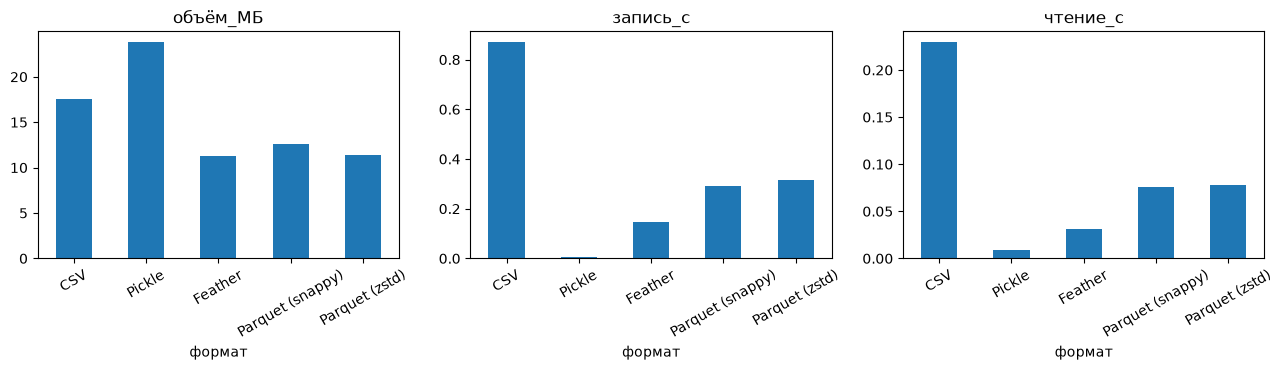

In [37]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, col in zip(axes, ["объём_МБ", "запись_с", "чтение_с"]):
    res[col].plot.bar(ax=ax, title=col, rot=30)
plt.tight_layout()
Path("../docs").mkdir(exist_ok=True)
plt.savefig("../docs/formats.png", dpi=150)
plt.show()

In [38]:
a = clean_final
b = pd.read_parquet("../data/interim/run1.parquet")
c = pd.read_parquet("../data/interim/run2.parquet")
print(a.shape, b.shape, c.shape)
pd.testing.assert_frame_equal(a, b)
pd.testing.assert_frame_equal(b, c)
print("блокнот и сценарий совпадают; повторный запуск даёт тот же результат")

(1089, 2619) (1089, 2619) (1089, 2619)
блокнот и сценарий совпадают; повторный запуск даёт тот же результат


In [39]:
from src.cleaning import column_units
import time, statistics

def med(fn, n=3):
    fn(); ts = []
    for _ in range(n):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return statistics.median(ts)

P = Path("../data/interim/run1.parquet")
base = pd.read_parquet(P)
print(f"файл: {P.stat().st_size/1024**2:.1f} МБ | память: {base.memory_usage(deep=True).sum()/1024**2:.1f} МБ")
print(f"чтение: {med(lambda: pd.read_parquet(P)):.3f} с | "
      f"группировка: {med(lambda: base.groupby('gc_cnt_gad_2025')['gc_pop_tot_2025'].median()):.4f} с")

dt = base.dtypes.astype(str)
mem = base.memory_usage(deep=True, index=False)
display(pd.DataFrame({"столбцов": dt.value_counts(),
                      "память_МБ": (mem.groupby(dt.values).sum() / 1024**2).round(2)}))

units = column_units([c.upper() for c in base.columns], sheets["Index"])
units = {k.lower(): v for k, v in units.items()}
num = base.select_dtypes("number")
inv = pd.DataFrame({"тип": dt[num.columns].values,
                    "единица": [units.get(c) or "нет в Index" for c in num.columns],
                    "макс": num.abs().max().values})
display(inv.groupby(["единица", "тип"]).agg(столбцов=("макс", "size"), макс=("макс", "max"))
        .sort_values("макс", ascending=False))

файл: 11.3 МБ | память: 21.9 МБ
чтение: 0.077 с | группировка: 0.0004 с


,столбцов,память_МБ
bool,13,0.01
float64,1800,14.96
int64,789,6.56
str,17,0.38


столбцов          макс
единица                    тип                            
PPP                        int64           7  5.520000e+11
m3                         int64         109  8.520085e+09
PPP                        float64         7  7.744656e+08
m2                         int64         508  6.762673e+08
                           float64        72  1.022340e+08
m                          float64        15  4.370608e+07
ton/year                   float64       329  3.986596e+07
num inhabitants            float64       219  1.951976e+07
number of people           float64         1  1.948516e+07
нет в Index                float64       196  1.456770e+07
                           int64          34  1.220125e+07
num. devices               float64         8  5.649690e+05
hectares                   float64        30  1.766413e+05
mm year-1                  float64        18  2.583421e+04
-                          int64          17  8.408000e+03
num people                 int64           7  6.510000e+03
Number of premature deaths float64         5  6.443000e+03
num events                 int64          37  4.728000e+03
ton/(year x person)        float64        28  2.224427e+03
km2                        int64          47  2.186000e+03
year                       int64           2  2.030000e+03
num events                 float64         3  1.910000e+03
hectares                   int64           3  1.184000e+03
ms                         float64         8  9.290000e+02
num facilities             float64         2  8.710000e+02
°C                         float64        31  8.019370e+02
m2/person                  float64        36  5.737100e+02
Mbps                       float64        16  4.938900e+02
Num. of days               int64           6  3.650000e+02
%                          float64       604  2.000000e+02
                           int64           4  1.000000e+02
years                      float64        51  8.445300e+01
µg/m3                      int64           5  4.700000e+01
num hazards                float64        32  2.600000e+01
m/s                        float64         5  1.237800e+01
US$                        float64        10  1.078000e+01
num facilities/km2         float64         2  6.444444e+00
kWh/kWp                    float64         1  6.129000e+00
mm/year                    float64         1  5.577000e+00
num fires                  int64           3  5.000000e+00
dimensionless              float64        36  5.000000e+00
-                          float64        30  1.000000e+00
°C/year                    float64         1  3.000000e-02
m/m2                       float64         1  2.699023e-02
num facilities/person      float64         2  7.484240e-04